# Comparação de Algoritmos de Agrupamento para Identificação de Candidatos a Microsserviços

## Projeto Final - Mineração de Dados (PPGCC)

## João Víctor Gomes de Oliveira

**Objeto de estudo:** FTGO (Food To Go).

**Questão de pesquisa:** Qual a contribuição das fontes de informação (requisitos, diagramas de casos de uso e de classes), individualmente, em combinação e em conjunto, para a identificação de candidatos a microsserviços?

**Fluxo de trabalho:** 0. Configuração; 1. Entrada de Dados; 2. Pré-processamento; 3. Mineração de Dados; 4. Pós-processamento; e 5. Visualização e Análise.

# 0. Configuração

Nesta seção instalamos as dependências, importamos as bibliotecas, definimos os parâmetros globais do experimento (`CONFIG`) e as constantes usadas ao longo do notebook, e fixamos as sementes para garantir reprodutibilidade.

In [ ]:
# leidenalg e python-igraph: algoritmo Leiden
# sentence-transformers: embeddings multilíngues
!pip install -q sentence-transformers python-igraph leidenalg

In [ ]:
import os
import re
import random
import shutil
import unicodedata
import warnings

import numpy as np
import pandas as pd
import networkx as nx
import igraph as ig
import leidenalg
import matplotlib.pyplot as plt

from IPython.display import display
from google.colab import files
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
    davies_bouldin_score,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram

In [ ]:
# Parâmetros globais
CONFIG = {
    "seed": 42,

    # Arquivos de entrada
    "requirements_file": "FTGO-Requirements.csv",
    "usecase_file": "FTGO-Usecase-diagram.puml",
    "class_file": "FTGO-Class-diagram.puml",
    "ground_truth_file": "FTGO-GroundTruth.csv",  # gerado

    # Embeddings (modelo multilíngue: pt-br + inglês)
    "embedding_model": "paraphrase-multilingual-mpnet-base-v2",

    # Cenários: fontes usadas em cada um (individuais, combinações e conjunto)
    "scenarios": {
        "S1": ["requirements"],
        "S2": ["usecases"],
        "S3": ["classes"],
        "S4": ["requirements", "usecases"],
        "S5": ["requirements", "classes"],
        "S6": ["usecases", "classes"],
        "S7": ["requirements", "usecases", "classes"],
    },

    # Microsserviços do ground truth e pacotes de classes fora do agrupamento
    "services": ["Consumer Service", "Restaurant Service", "Order Service", "Delivery Service"],
    "exclude_class_packages": ["Objetos de Valor"],  # transversais, sem dono único

    # Algoritmos
    "n_clusters": 4,              # k do K-Means e do Agglomerative (= nº de serviços)
    "linkage": "ward",
    "dbscan_min_samples": 2,
    "dbscan_eps_percentile": 75,  # eps = percentil da distância ao vizinho mais próximo (sem ground truth)
    "knn_k": 5,                   # vizinhos do grafo kNN (usado só pelo Leiden)
    "leiden_resolution": 1.0,
}

# Constantes de análise e visualização
ALGORITHMS = ["K-Means", "Agglomerative", "DBSCAN", "Leiden"]
METRICS = ["ARI", "NMI", "Pureza", "Silhouette", "Davies-Bouldin",
           "Coesão estrutural", "Acoplamento estrutural", "Modularidade", "Coesão semântica"]
LOWER_IS_BETTER = {"Davies-Bouldin", "Acoplamento estrutural"}

# Fontes isoladas que compõem cada cenário combinado
COMPONENTS = {"S4": ["S1", "S2"], "S5": ["S1", "S3"], "S6": ["S2", "S3"], "S7": ["S1", "S2", "S3"]}
GROUPS = {"S1": "Individual", "S2": "Individual", "S3": "Individual",
          "S4": "Combinação", "S5": "Combinação", "S6": "Combinação", "S7": "Conjunto"}
GROUP_COLORS = {"Individual": "#4c72b0", "Combinação": "#dd8452", "Conjunto": "#55a868"}
SERVICE_COLORS = dict(zip(CONFIG["services"], ["#4c72b0", "#dd8452", "#55a868", "#c44e52"]))
ALGO_MARKERS = {"K-Means": "o", "Agglomerative": "s", "DBSCAN": "^", "Leiden": "D"}

# Fixa as sementes
random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])

print("Configuração carregada. Cenários:", list(CONFIG["scenarios"]))

Configuração carregada. Cenários: ['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7']


# 1. Entrada de Dados

Carregamos os três artefatos do FTGO (requisitos em CSV; diagramas de casos de uso e de classes em PlantUML), extraímos itens e relações e geramos o gabarito (*ground truth*), isto é, o microsserviço esperado para cada item. Requisitos não funcionais e o pacote "Objetos de Valor" ficam fora do agrupamento por serem transversais.

In [ ]:
# Envie os 3 arquivos de entrada
required = [CONFIG["requirements_file"], CONFIG["usecase_file"], CONFIG["class_file"]]

if not all(os.path.exists(f) for f in required):
    files.upload()

for f in required + [CONFIG["ground_truth_file"]]:
    print(f, "->", "OK" if os.path.exists(f) else "não encontrado")

Saving FTGO-Class-diagram.puml to FTGO-Class-diagram.puml
Saving FTGO-Requirements.csv to FTGO-Requirements.csv
Saving FTGO-Usecase-diagram.puml to FTGO-Usecase-diagram.puml
FTGO-Requirements.csv -> OK
FTGO-Usecase-diagram.puml -> OK
FTGO-Class-diagram.puml -> OK
FTGO-GroundTruth.csv -> não encontrado


In [ ]:
# Funcionais entram no agrupamento; não funcionais (transversais) ficam à parte
df_req_all = pd.read_csv(CONFIG["requirements_file"])
df_req_all.columns = ["item_id", "type", "category", "text"]

df_req = df_req_all[df_req_all["type"] == "Funcional"].reset_index(drop=True)
df_nfr = df_req_all[df_req_all["type"] == "Não funcional"].reset_index(drop=True)

print(f"Requisitos funcionais (S1): {len(df_req)} | Não funcionais (fora do agrupamento): {len(df_nfr)}")

Requisitos funcionais (S1): 27 | Não funcionais (fora do agrupamento): 10


In [ ]:
def parse_usecase_diagram(path):
    """Extrai casos de uso, associações com atores e relações <<include>> de um .puml."""
    content = open(path, encoding="utf-8").read()

    # usecase "Nome" as UCxx (o \n literal do PlantUML vira espaço)
    usecases = [{"item_id": uc_id, "text": name.replace("\\n", " ").strip()}
                for name, uc_id in re.findall(r'usecase\s+"([^"]+)"\s+as\s+(UC\d+)', content)]

    actors = re.findall(r'^(Consumidor|Restaurante|Entregador)\s+--\s+(UC\d+)', content, flags=re.M)
    includes = re.findall(r'(UC\d+)\s+\.\.>\s+(UC\d+)\s*:\s*<<include>>', content)
    return usecases, {uc: actor for actor, uc in actors}, includes

usecases, uc_actor_map, uc_includes = parse_usecase_diagram(CONFIG["usecase_file"])

df_uc = pd.DataFrame(usecases)
df_uc["actor"] = df_uc["item_id"].map(uc_actor_map).fillna("(incluído)")

print(f"Casos de uso (S2): {len(df_uc)} | Relações include: {len(uc_includes)}")

Casos de uso (S2): 22 | Relações include: 5


In [ ]:
def parse_class_diagram(path):
    """Extrai classes/enums (pacote, atributos, operações, valores) e relações de um .puml."""
    classes, relations = [], []
    package, current = None, None
    rel_pattern = re.compile(r'^(\w+)\s+(?:"[^"]*"\s+)?(\*--|-->|--)\s+(?:"[^"]*"\s+)?(\w+)')

    for raw in open(path, encoding="utf-8"):
        line = raw.strip()

        if not line or line.startswith("'"):
            continue

        m = re.match(r'package\s+"(.+?)"\s*\{', line)

        if m:
            package = m.group(1)
            continue

        m = re.match(r'(class|enum)\s+(\w+)(?:\s+<<(\w+)>>)?\s*\{', line)

        if m:
            current = {"kind": m.group(1), "name": m.group(2), "package": package,
                       "attributes": [], "methods": [], "values": []}

            continue

        if current is not None:  # dentro de uma classe ou enum
            if line == "}":
                classes.append(current)
                current = None
            elif line.startswith(("-", "+")):
                if "(" in line:
                    current["methods"].append(re.match(r'[-+]\s*(\w+)\(', line).group(1))
                else:
                    current["attributes"].append(re.match(r'[-+]\s*(\w+)', line).group(1))
            elif current["kind"] == "enum":
                current["values"].append(line)
            continue

        if line == "}":  # fim de pacote
            package = None
            continue

        m = rel_pattern.match(line)

        if m:
            relations.append({"source": m.group(1), "target": m.group(3), "type": m.group(2)})

    return classes, relations

classes, class_relations = parse_class_diagram(CONFIG["class_file"])

df_cls_all = pd.DataFrame(classes)
df_cls_all["item_id"] = "CL_" + df_cls_all["name"]
df_class_rel = pd.DataFrame(class_relations)

# Remove pacotes transversais (objetos de valor) do agrupamento
df_cls = df_cls_all[~df_cls_all["package"].isin(CONFIG["exclude_class_packages"])].reset_index(drop=True)

print(f"Classes no diagrama: {len(df_cls_all)} | no agrupamento (S3): {len(df_cls)} | Relações: {len(df_class_rel)}")

Classes no diagrama: 16 | no agrupamento (S3): 13 | Relações: 21


In [ ]:
# Mapeamento item_id -> (microsserviço, classes relacionadas).
# É a base das métricas externas (ARI, NMI, Pureza) e do grafo estrutural.
CS, RS, OS, DS = CONFIG["services"]

ground_truth = {
    # --- Requisitos funcionais ---
    "RF01": (CS, "Consumer"), "RF02": (CS, "Consumer"),
    "RF03": (RS, "Restaurant;RestaurantMenu"), "RF04": (RS, "Restaurant"),
    "RF05": (RS, "MenuItem"), "RF06": (RS, "Restaurant;MenuItem"),
    "RF07": (OS, "Order;OrderLineItem;Consumer;Restaurant"),
    "RF08": (OS, "Order;Consumer;Restaurant;MenuItem"),
    "RF09": (OS, "Order;OrderLineItem"), "RF10": (OS, "Order"),
    "RF11": (OS, "Order;Consumer"), "RF12": (OS, "Order;OrderState"),
    "RF13": (OS, "Order;OrderLineItem"),
    "RF14": (OS, "Order;OrderState;Restaurant"),
    "RF15": (OS, "Order;OrderState"), "RF16": (OS, "Order;OrderState"),
    "RF17": (OS, "Order;OrderState;Courier"), "RF18": (OS, "Order;OrderState"),
    "RF19": (DS, "Courier"), "RF20": (DS, "Courier"), "RF21": (DS, "Courier"),
    "RF22": (DS, "Courier;Order"), "RF23": (DS, "Courier;Plan;Action"),
    "RF24": (DS, "Courier;Plan;Action;Order"),
    "RF25": (OS, "Order"), "RF26": (OS, "Order;OrderState"),
    "RF27": (OS, "Order;Restaurant;Courier"),

    # --- Casos de uso ---
    "UC01": (CS, "Consumer"), "UC02": (CS, "Consumer"),
    "UC03": (RS, "Restaurant"), "UC04": (RS, "Restaurant;RestaurantMenu;MenuItem"),
    "UC05": (OS, "Order;OrderLineItem;Consumer;Restaurant"),
    "UC06": (OS, "Order;Consumer;MenuItem"), "UC07": (OS, "Order;OrderLineItem"),
    "UC08": (OS, "Order;OrderState"), "UC09": (OS, "Order;OrderLineItem"),
    "UC10": (OS, "Order;OrderState"), "UC11": (RS, "Restaurant"),
    "UC12": (OS, "Order;Restaurant"), "UC13": (OS, "Order;OrderState"),
    "UC14": (DS, "Order;Courier;Plan"),
    "UC15": (OS, "Order;OrderState"), "UC16": (OS, "Order;OrderState"),
    "UC17": (DS, "Courier"), "UC18": (DS, "Courier"),
    "UC19": (DS, "Courier;Plan;Action"),
    "UC20": (DS, "Courier;Action;Order"), "UC21": (DS, "Courier;Action;Order"),
    "UC22": (OS, "Order;OrderState"),

    # --- Classes ---
    "CL_Consumer": (CS, "Consumer"),
    "CL_Restaurant": (RS, "Restaurant"), "CL_RestaurantMenu": (RS, "RestaurantMenu"),
    "CL_MenuItem": (RS, "MenuItem"),
    "CL_Order": (OS, "Order"), "CL_OrderLineItems": (OS, "OrderLineItems"),
    "CL_OrderLineItem": (OS, "OrderLineItem"), "CL_DeliveryInformation": (OS, "DeliveryInformation"),
    "CL_OrderState": (OS, "OrderState"),
    "CL_Courier": (DS, "Courier"), "CL_Plan": (DS, "Plan"),
    "CL_Action": (DS, "Action"), "CL_ActionType": (DS, "ActionType"),
}

# Gera o CSV
source_of = lambda i: "requirements" if i.startswith("RF") else ("usecases" if i.startswith("UC") else "classes")
pd.DataFrame([{"item_id": i, "source": source_of(i), "label": lbl, "related_classes": cls}
              for i, (lbl, cls) in ground_truth.items()]).to_csv(CONFIG["ground_truth_file"], index=False)
print("Ground Truth gerado.")

Ground Truth gerado.


In [ ]:
df_gt = pd.read_csv(CONFIG["ground_truth_file"])

expected_ids = set(df_req["item_id"]) | set(df_uc["item_id"]) | set(df_cls["item_id"])
missing = expected_ids - set(df_gt["item_id"])
extra = set(df_gt["item_id"]) - expected_ids
invalid = set(df_gt["label"]) - set(CONFIG["services"])

assert not missing, f"Itens sem rótulo: {sorted(missing)}"
assert not extra, f"Rótulos sem item correspondente: {sorted(extra)}"
assert not invalid, f"Rótulos fora da lista de serviços: {invalid}"

print(f"Ground truth validado: {len(df_gt)} itens\n")
print(pd.crosstab(df_gt["source"], df_gt["label"], margins=True))

Ground truth validado: 62 itens

label         Consumer Service  Delivery Service  Order Service  \
source                                                            
classes                      1                 4              5   
requirements                 2                 6             15   
usecases                     2                 6             11   
All                          5                16             31   

label         Restaurant Service  All  
source                                 
classes                        3   13  
requirements                   4   27  
usecases                       3   22  
All                           10   62  


# 2. Pré-processamento

Convertemos os itens em textos curtos, aplicamos normalização mínima (adequada a transformers: sem remover stopwords, sem stemming, mantendo acentos e caixa), geramos **um embedding por item** e montamos os sete cenários: individuais (S1 a S3), combinações (S4 a S6) e conjunto (S7). Um cenário é apenas um subconjunto de itens no mesmo espaço de embeddings.

In [ ]:
def normalize_text(text):
    """Normalização mínima: Unicode NFC, quebras de linha e espaços repetidos."""
    text = unicodedata.normalize("NFC", str(text))
    text = text.replace("\\n", " ").replace("\n", " ")

    return re.sub(r"\s+", " ", text).strip()

def split_identifier(name):
    """CamelCase e snake_case viram palavras; constantes de enum em maiúsculas viram minúsculas."""
    if name.isupper():
        name = name.lower()

    return re.sub(r"(?<=[a-z0-9])(?=[A-Z])", " ", name.replace("_", " "))

def class_to_text(row):
    """Descreve uma classe com nome, atributos e operações (ou valores, no caso de enums)."""
    name = split_identifier(row["name"])

    if row["kind"] == "enum":
        return f"Enumeração {name}. Valores: {', '.join(split_identifier(v) for v in row['values'])}."
    text = f"Classe {name}."

    if row["attributes"]:
        text += f" Atributos: {', '.join(split_identifier(a) for a in row['attributes'])}."

    if row["methods"]:
        text += f" Operações: {', '.join(split_identifier(m) for m in row['methods'])}."

    return text

# Tabela única: um registro por artefato, com texto normalizado e ground truth
df_items = pd.concat([
    df_req.assign(source="requirements")[["item_id", "source", "text"]],
    df_uc.assign(source="usecases")[["item_id", "source", "text"]],
    df_cls.assign(source="classes", text=df_cls.apply(class_to_text, axis=1))[["item_id", "source", "text"]],
], ignore_index=True)
df_items["text"] = df_items["text"].apply(normalize_text)
df_items = df_items.merge(df_gt[["item_id", "label", "related_classes"]], on="item_id", how="left")
assert df_items["label"].notna().all(), "Há itens sem rótulo no ground truth"

print(df_items["source"].value_counts().to_string())

source
requirements    27
usecases        22
classes         13


In [ ]:
def embed_items(model_name, prefix=""):
    """Gera um embedding normalizado por item (produto escalar = similaridade de cosseno)."""
    model = SentenceTransformer(model_name)
    vectors = model.encode([prefix + t for t in df_items["text"]],
                           normalize_embeddings=True, show_progress_bar=False)

    return dict(zip(df_items["item_id"], vectors))

def scenario_matrix(items, emb):
    """Matriz de embeddings dos itens de um cenário, na mesma ordem de `items`."""
    return np.vstack([emb[i] for i in items["item_id"]])

emb_by_id = embed_items(CONFIG["embedding_model"])

scenarios = {}

for name, sources in CONFIG["scenarios"].items():
    items = df_items[df_items["source"].isin(sources)].reset_index(drop=True)
    scenarios[name] = {"items": items, "X": scenario_matrix(items, emb_by_id), "y_true": items["label"].values}

summary = pd.DataFrame({
    name: {"fontes": " + ".join(CONFIG["scenarios"][name]), "itens": len(s["items"]),
           **pd.Series(s["y_true"]).value_counts().to_dict()}

    for name, s in scenarios.items()
}).T.fillna(0)
summary

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

/tmp/ipykernel_736/3223655452.py:26: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  }).T.fillna(0)


,fontes,itens,Order Service,Delivery Service,Restaurant Service,Consumer Service
S1,requirements,27,15,6,4,2
S2,usecases,22,11,6,3,2
S3,classes,13,5,4,3,1
S4,requirements + usecases,49,26,12,7,4
S5,requirements + classes,40,20,10,7,3
S6,usecases + classes,35,16,10,6,3
S7,requirements + usecases + classes,62,31,16,10,5


In [ ]:
def diagnose(sc, n_neighbors=3):
    """Separação por serviço, efeito de fonte e pureza dos vizinhos mais próximos (vs. acaso)."""
    X, y, src = sc["X"], sc["y_true"], sc["items"]["source"].values
    sim = cosine_similarity(X)
    off = ~np.eye(len(sim), dtype=bool)
    same_y = y[:, None] == y[None, :]
    same_s = src[:, None] == src[None, :]

    s = sim.copy()
    np.fill_diagonal(s, -1)
    nn = np.argsort(-s, axis=1)[:, :n_neighbors]

    p = pd.Series(y).value_counts(normalize=True)

    return {
        "itens": len(y),
        "sim_mesmo_servico": sim[same_y & off].mean(),
        "sim_outro_servico": sim[~same_y].mean(),
        "sim_mesma_fonte": sim[same_s & off].mean(),
        "sim_outra_fonte": sim[~same_s].mean() if (~same_s).any() else np.nan,
        "pureza_vizinhos": (y[nn] == y[:, None]).mean(),
        "pureza_acaso": (p ** 2).sum(),
    }

pd.DataFrame({name: diagnose(sc) for name, sc in scenarios.items()}).T.round(3)

,itens,sim_mesmo_servico,sim_outro_servico,sim_mesma_fonte,sim_outra_fonte,pureza_vizinhos,pureza_acaso
S1,27.0,0.621,0.540,0.569,NaN,0.605,0.385
S2,22.0,0.547,0.426,0.465,NaN,0.667,0.351
S3,13.0,0.588,0.466,0.495,NaN,0.538,0.302
S4,49.0,0.532,0.438,0.528,0.417,0.701,0.369
S5,40.0,0.513,0.423,0.556,0.327,0.617,0.349
S6,35.0,0.455,0.362,0.473,0.302,0.724,0.327
S7,62.0,0.481,0.389,0.524,0.364,0.688,0.349


# 3. Mineração de Dados

Aplicamos quatro algoritmos (K-Means, Agglomerative Clustering, DBSCAN e Leiden) aos sete cenários. O `eps` do DBSCAN é definido por uma regra única (percentil da distância ao vizinho mais próximo), sem consultar o ground truth. O Leiden usa um grafo kNN de similaridade. K-Means e Agglomerative recebem k = 4; DBSCAN e Leiden descobrem o número de clusters sozinhos.

In [ ]:
def build_knn_graph(X, k):
    """Grafo kNN (igraph) com peso = similaridade de cosseno; arestas simetrizadas (união)."""
    k = min(k, len(X) - 1)
    sim = cosine_similarity(X)
    np.fill_diagonal(sim, -1)
    neighbors = np.argsort(-sim, axis=1)[:, :k]

    edges = {}
    for i, row in enumerate(neighbors):
        for j in row:
            edges[tuple(sorted((i, int(j))))] = max(sim[i, j], 0.0)

    g = ig.Graph(n=len(X), edges=list(edges.keys()))
    g.es["weight"] = list(edges.values())

    return g

def estimate_eps(X, min_samples, percentile):
    """eps do DBSCAN: percentil da distância (cosseno) ao vizinho que completa min_samples."""
    nn = NearestNeighbors(n_neighbors=min_samples, metric="cosine").fit(X)
    distances, _ = nn.kneighbors(X)  # coluna 0 = o próprio item

    return float(np.percentile(distances[:, -1], percentile))

def cluster_all(X, eps_pct=None, knn_k=None, seed=None):
    """Executa os 4 algoritmos. Parâmetros omitidos usam o CONFIG (a análise de sensibilidade os varia)."""
    eps_pct = CONFIG["dbscan_eps_percentile"] if eps_pct is None else eps_pct
    knn_k = CONFIG["knn_k"] if knn_k is None else knn_k
    seed = CONFIG["seed"] if seed is None else seed

    eps = estimate_eps(X, CONFIG["dbscan_min_samples"], eps_pct)
    leiden = leidenalg.find_partition(
        build_knn_graph(X, knn_k),
        leidenalg.RBConfigurationVertexPartition,  # modularidade com parâmetro de resolução
        weights="weight", resolution_parameter=CONFIG["leiden_resolution"], seed=seed)

    return {
        "K-Means": KMeans(n_clusters=CONFIG["n_clusters"], n_init=10, random_state=seed).fit_predict(X),
        # Ward usa distância euclidiana; com vetores normalizados equivale ao cosseno
        "Agglomerative": AgglomerativeClustering(n_clusters=CONFIG["n_clusters"],
                                                 linkage=CONFIG["linkage"]).fit_predict(X),
        "DBSCAN": DBSCAN(eps=eps, min_samples=CONFIG["dbscan_min_samples"], metric="cosine").fit_predict(X),
        "Leiden": np.array(leiden.membership),
    }

In [ ]:
# results[(cenário, algoritmo)] = rótulos de cluster (-1 = ruído do DBSCAN)
results = {}

for sc_name, sc in scenarios.items():
    for algo, labels in cluster_all(sc["X"]).items():
        results[(sc_name, algo)] = labels

print(f"Execuções concluídas: {len(results)} (7 cenários x 4 algoritmos)")

Execuções concluídas: 28 (7 cenários x 4 algoritmos)


# 4. Pós-processamento

Removemos os itens classificados como ruído (rótulo -1 do DBSCAN). Geramos dois conjuntos:

- **`clean` (resultado principal):** cada algoritmo é avaliado nos seus próprios itens.
- **`common` (comparação justa):** todos os algoritmos são avaliados nos itens retidos pelo DBSCAN.

In [ ]:
def make_runs(sc, X, labels_by_algo, mode):
    """Monta as execuções de um cenário sem ruído. mode='clean': máscara de cada algoritmo;
    mode='common': máscara do DBSCAN aplicada a todos. Preserva a máscara (usada nas métricas estruturais)."""
    db_mask = labels_by_algo["DBSCAN"] != -1
    runs = {}

    for algo, labels in labels_by_algo.items():
        mask = (labels != -1) if mode == "clean" else db_mask
        runs[algo] = {"mask": mask, "items": sc["items"][mask].reset_index(drop=True), "X": X[mask],
                      "labels": labels[mask], "y_true": sc["y_true"][mask], "noise_pct": 100 * (~mask).mean()}

    return runs

clean, common = {}, {}

for sc_name, sc in scenarios.items():
    by_algo = {a: results[(sc_name, a)] for a in ALGORITHMS}

    for algo, run in make_runs(sc, sc["X"], by_algo, "clean").items():
        clean[(sc_name, algo)] = run

    for algo, run in make_runs(sc, sc["X"], by_algo, "common").items():
        common[(sc_name, algo)] = run

print(f"Execuções: {len(clean)} (principal) e {len(common)} (subconjunto comum)")

Execuções: 28 (principal) e 28 (subconjunto comum)


In [ ]:
# O ground truth é usado só para descrever, nunca para ajustar parâmetros
noise_rows = []

for sc_name, sc in scenarios.items():
    removed = sc["items"][~clean[(sc_name, "DBSCAN")]["mask"]]
    noise_rows += [{"cenário": sc_name, "item_id": r["item_id"], "fonte": r["source"], "serviço": r["label"]}
                   for _, r in removed.iterrows()]

df_noise = pd.DataFrame(noise_rows)

s7 = df_noise[df_noise["cenário"] == "S7"]
print("Ruído por fonte (S7):\n", s7["fonte"].value_counts().to_string())
print("\nRuído por serviço (S7):\n", s7["serviço"].value_counts().to_string())

Ruído por fonte (S7):
 fonte
usecases        7
classes         6
requirements    3

Ruído por serviço (S7):
 serviço
Order Service         8
Delivery Service      6
Restaurant Service    1
Consumer Service      1


# 5. Visualização e Análise

## 5.1 Métricas

Calculamos as nove métricas para cada cenário e algoritmo: externas (ARI, NMI, Pureza), internas (Silhouette, Davies-Bouldin, Coesão semântica) e estruturais (Coesão estrutural, Acoplamento estrutural, Modularidade). As estruturais usam um grafo derivado do **diagrama de classes**, e não dos embeddings, para evitar circularidade com os algoritmos.

In [ ]:
# Pares de classes ligados no diagrama (não direcionado)
class_links = {frozenset((r.source, r.target)) for r in df_class_rel.itertuples()}

def build_structural_matrix(items):
    """Peso entre dois itens = nº de pares de classes (uma de cada item) iguais ou ligadas no
    diagrama, +1 por <<include>> entre casos de uso. Normalizado em [0, 1]."""
    cls_sets = [set(c.split(";")) for c in items["related_classes"]]
    n = len(items)
    W = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            W[i, j] = W[j, i] = sum(1 for a in cls_sets[i] for b in cls_sets[j]
                                    if a == b or frozenset((a, b)) in class_links)

    pos = {item_id: k for k, item_id in enumerate(items["item_id"])}

    for a, b in uc_includes:
        if a in pos and b in pos:
            W[pos[a], pos[b]] += 1
            W[pos[b], pos[a]] += 1

    return W / W.max() if W.max() > 0 else W

structural_W = {name: build_structural_matrix(sc["items"]) for name, sc in scenarios.items()}

In [ ]:
def purity_score(y_true, labels):
    """Fração de itens com o rótulo majoritário do seu cluster."""
    ct = pd.crosstab(labels, y_true)
    return ct.max(axis=1).sum() / ct.values.sum()

def semantic_cohesion(X, labels):
    """Similaridade de cosseno média entre pares do mesmo cluster (média dos clusters com 2+ itens)."""
    values = []
    for c in np.unique(labels):
        Xc = X[labels == c]

        if len(Xc) >= 2:
            sim = cosine_similarity(Xc)
            values.append(sim[~np.eye(len(Xc), dtype=bool)].mean())

    return np.mean(values) if values else np.nan

def structural_metrics(W, labels):
    """Coesão (peso médio interno), acoplamento (peso médio entre clusters) e modularidade de Newman."""
    clusters = np.unique(labels)
    idx = {c: np.where(labels == c)[0] for c in clusters}
    total = W.sum()

    cohesion = [W[np.ix_(i, i)].sum() / (len(i) * (len(i) - 1)) for i in idx.values() if len(i) >= 2]
    coupling = [W[np.ix_(idx[a], idx[b])].mean() for k, a in enumerate(clusters) for b in clusters[k + 1:]]
    modularity = (sum(W[np.ix_(i, i)].sum() / total - (W[i].sum() / total) ** 2 for i in idx.values())
                  if total > 0 else np.nan)

    return (np.mean(cohesion) if cohesion else np.nan,
            np.mean(coupling) if coupling else np.nan, modularity)

def evaluate(run, W_full):
    """Calcula as 9 métricas de uma execução (dados já sem ruído)."""
    labels, y, X = run["labels"], run["y_true"], run["X"]
    W = W_full[np.ix_(run["mask"], run["mask"])]  # grafo restrito aos itens mantidos
    k = len(np.unique(labels))
    can_score = 2 <= k <= len(labels) - 1          # Silhouette e Davies-Bouldin exigem 2..n-1 clusters
    coh, cpl, mod = structural_metrics(W, labels)

    return {
        "ARI": adjusted_rand_score(y, labels),
        "NMI": normalized_mutual_info_score(y, labels),
        "Pureza": purity_score(y, labels),
        "Silhouette": silhouette_score(X, labels, metric="cosine") if can_score else np.nan,
        "Davies-Bouldin": davies_bouldin_score(X, labels) if can_score else np.nan,
        "Coesão estrutural": coh,
        "Acoplamento estrutural": cpl,
        "Modularidade": mod,
        "Coesão semântica": semantic_cohesion(X, labels),
        "clusters": k,
        "ruído_%": run["noise_pct"],
    }

def evaluate_all(runs):
    """Avalia todas as execuções (cenário x algoritmo) e devolve uma tabela."""
    return pd.DataFrame([{"cenário": sc, "algoritmo": algo, **evaluate(run, structural_W[sc])}
                         for (sc, algo), run in runs.items()])

In [ ]:
df_metrics = evaluate_all(clean)          # principal: cada algoritmo nos seus itens
df_metrics_common = evaluate_all(common)  # comparação justa: todos nos itens retidos pelo DBSCAN

df_metrics_common.round(3)
# df_metrics.round(3)  # para ver também o resultado principal

,cenário,algoritmo,ARI,NMI,Pureza,Silhouette,Davies-Bouldin,Coesão estrutural,Acoplamento estrutural,Modularidade,Coesão semântica,clusters,ruído_%
0,S1,K-Means,0.135,0.358,0.600,0.433,1.134,0.264,0.191,0.035,0.778,3,25.926
1,S1,Agglomerative,0.135,0.358,0.600,0.433,1.134,0.264,0.191,0.035,0.778,3,25.926
2,S1,DBSCAN,0.108,0.420,0.700,0.417,1.083,0.440,0.256,0.012,0.820,5,25.926
3,S1,Leiden,0.147,0.358,0.600,0.415,1.256,0.273,0.218,0.020,0.764,3,25.926
4,S2,K-Means,0.794,0.862,0.941,0.463,1.087,0.358,0.151,0.010,0.789,4,22.727
5,S2,Agglomerative,0.674,0.744,0.824,0.391,1.385,0.317,0.185,-0.001,0.721,3,22.727
6,S2,DBSCAN,0.684,0.800,0.941,0.344,1.086,0.437,0.267,-0.026,0.797,6,22.727
7,S2,Leiden,0.277,0.525,0.706,0.224,1.499,0.423,0.359,-0.027,0.683,3,22.727
8,S3,K-Means,0.432,0.618,0.800,0.368,1.280,0.500,0.111,0.225,0.724,3,23.077
9,S3,Agglomerative,0.659,0.793,0.900,0.329,1.330,0.556,0.120,0.255,0.710,3,23.077


In [ ]:
def evaluate_references(n_random=100):
    """Avalia o ground truth (teto aproximado) e partições aleatórias com os mesmos tamanhos (piso)."""
    rng = np.random.default_rng(CONFIG["seed"])
    rows = []

    for sc_name, sc in scenarios.items():
        base = {"mask": np.ones(len(sc["items"]), dtype=bool), "X": sc["X"],
                "y_true": sc["y_true"], "noise_pct": 0.0}
        W = structural_W[sc_name]
        rows.append({"cenário": sc_name, "referência": "Ground truth",
                     **evaluate({**base, "labels": sc["y_true"]}, W)})
        rand = [evaluate({**base, "labels": rng.permutation(sc["y_true"])}, W) for _ in range(n_random)]
        rows.append({"cenário": sc_name, "referência": "Aleatória (média)", **pd.DataFrame(rand).mean().to_dict()})

    return pd.DataFrame(rows)

df_reference = evaluate_references()
df_reference[["cenário", "referência"] + METRICS].round(3)

,cenário,referência,ARI,NMI,Pureza,Silhouette,Davies-Bouldin,Coesão estrutural,Acoplamento estrutural,Modularidade,Coesão semântica
0,S1,Ground truth,1.000,1.000,1.000,0.049,1.985,0.240,0.094,0.027,0.716
1,S1,Aleatória (média),0.012,0.167,0.577,-0.128,3.578,0.227,0.229,-0.030,0.571
2,S2,Ground truth,1.000,1.000,1.000,0.180,1.813,0.351,0.142,0.037,0.657
3,S2,Aleatória (média),-0.003,0.204,0.546,-0.119,3.101,0.300,0.305,-0.036,0.470
4,S3,Ground truth,1.000,1.000,1.000,0.181,1.601,0.522,0.061,0.346,0.638
5,S3,Aleatória (média),-0.033,0.297,0.535,-0.140,2.336,0.150,0.164,-0.118,0.491
6,S4,Ground truth,1.000,1.000,1.000,0.088,2.418,0.263,0.102,0.051,0.627
7,S4,Aleatória (média),-0.000,0.100,0.544,-0.086,4.923,0.236,0.235,-0.016,0.472
8,S5,Ground truth,1.000,1.000,1.000,0.060,2.632,0.171,0.059,0.064,0.589
9,S5,Aleatória (média),0.001,0.116,0.520,-0.099,4.609,0.135,0.136,-0.024,0.447


## 5.2 Tabelas, grafos e dendrogramas

Tabelas finais das nove métricas (resultado principal e subconjunto comum), efeito do subconjunto comum, mapas de calor, contribuição das fontes, dendrogramas do Agglomerative e grafos coloridos por cluster e por microsserviço do gabarito.

In [ ]:
def show_metric_tables(df, title):
    """Uma tabela por métrica (cenários x algoritmos), destacando o melhor valor de cada linha."""
    for m in METRICS:
        pv = df.pivot(index="cenário", columns="algoritmo", values=m).round(3)
        print(f"\n{title} | {m} ({'menor' if m in LOWER_IS_BETTER else 'maior'} é melhor)")
        styler = (pv.style.highlight_min(axis=1, color="red") if m in LOWER_IS_BETTER
                  else pv.style.highlight_max(axis=1, color="red"))

        display(styler)

show_metric_tables(df_metrics_common, "Subconjunto comum")
# show_metric_tables(df_metrics, "Principal")  # para ver também o resultado principal


Subconjunto comum | ARI (maior é melhor)


algoritmo,Agglomerative,DBSCAN,K-Means,Leiden
cenário,,,,
S1,0.135000,0.108000,0.135000,0.147000
S2,0.674000,0.684000,0.794000,0.277000
S3,0.659000,0.312000,0.432000,0.137000
S4,0.253000,0.108000,0.224000,0.264000
S5,0.101000,0.142000,0.153000,0.153000
S6,0.507000,0.332000,0.298000,0.464000
S7,0.242000,-0.047000,0.149000,0.163000



Subconjunto comum | NMI (maior é melhor)


algoritmo,Agglomerative,DBSCAN,K-Means,Leiden
cenário,,,,
S1,0.358000,0.420000,0.358000,0.358000
S2,0.744000,0.800000,0.862000,0.525000
S3,0.793000,0.509000,0.618000,0.399000
S4,0.446000,0.387000,0.434000,0.494000
S5,0.299000,0.407000,0.336000,0.336000
S6,0.642000,0.604000,0.385000,0.577000
S7,0.366000,0.250000,0.339000,0.349000



Subconjunto comum | Pureza (maior é melhor)


algoritmo,Agglomerative,DBSCAN,K-Means,Leiden
cenário,,,,
S1,0.600000,0.700000,0.600000,0.600000
S2,0.824000,0.941000,0.941000,0.706000
S3,0.900000,0.600000,0.800000,0.600000
S4,0.676000,0.622000,0.676000,0.784000
S5,0.533000,0.633000,0.600000,0.600000
S6,0.808000,0.769000,0.615000,0.769000
S7,0.609000,0.565000,0.565000,0.652000


... (8 outputs left out)


Subconjunto comum | Modularidade (maior é melhor)


algoritmo,Agglomerative,DBSCAN,K-Means,Leiden
cenário,,,,
S1,0.035000,0.012000,0.035000,0.020000
S2,-0.001000,-0.026000,0.010000,-0.027000
S3,0.255000,0.155000,0.225000,0.115000
S4,0.018000,0.010000,0.017000,0.018000
S5,0.028000,0.032000,0.047000,0.047000
S6,0.012000,0.001000,-0.010000,0.012000
S7,0.020000,-0.012000,0.021000,0.013000



Subconjunto comum | Coesão semântica (maior é melhor)


algoritmo,Agglomerative,DBSCAN,K-Means,Leiden
cenário,,,,
S1,0.778000,0.820000,0.778000,0.764000
S2,0.721000,0.797000,0.789000,0.683000
S3,0.710000,0.627000,0.724000,0.703000
S4,0.706000,0.715000,0.708000,0.719000
S5,0.715000,0.781000,0.696000,0.696000
S6,0.635000,0.776000,0.590000,0.643000
S7,0.654000,0.750000,0.638000,0.657000


In [ ]:
for m in ["ARI", "NMI"]:
    full = df_metrics.pivot(index="cenário", columns="algoritmo", values=m)
    comm = df_metrics_common.pivot(index="cenário", columns="algoritmo", values=m)
    print(f"\n{m}: diferença (subconjunto comum - principal)")
    display((comm - full).round(3))


ARI: diferença (subconjunto comum - principal)


algoritmo,Agglomerative,DBSCAN,K-Means,Leiden
cenário,,,,
S1,0.042,0.0,0.042,-0.026
S2,0.262,0.0,0.370,0.192
S3,0.284,0.0,0.226,0.034
S4,0.091,0.0,0.062,0.078
S5,0.015,0.0,-0.033,0.023
S6,0.298,0.0,0.166,0.195
S7,0.033,0.0,0.016,0.046



NMI: diferença (subconjunto comum - principal)


algoritmo,Agglomerative,DBSCAN,K-Means,Leiden
cenário,,,,
S1,0.007,0.0,0.007,-0.013
S2,0.188,0.0,0.332,0.196
S3,0.172,0.0,0.120,0.019
S4,0.107,0.0,0.098,0.098
S5,0.031,0.0,0.001,0.026
S6,0.244,0.0,0.119,0.135
S7,0.065,0.0,0.029,0.055


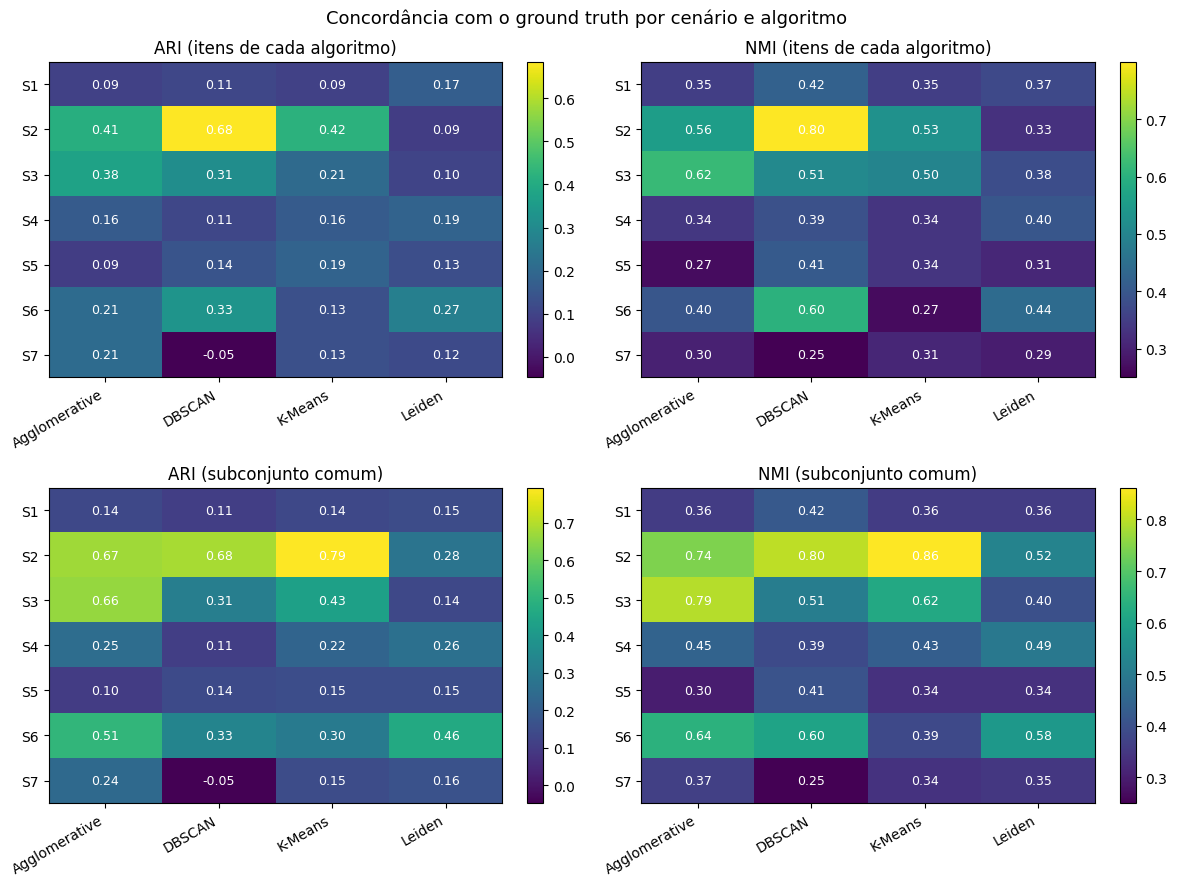

In [ ]:
def draw_heatmap(ax, df, metric, title):
    pv = df.pivot(index="cenário", columns="algoritmo", values=metric)
    im = ax.imshow(pv.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(pv.shape[1]))
    ax.set_xticklabels(pv.columns, rotation=30, ha="right")
    ax.set_yticks(range(pv.shape[0]))
    ax.set_yticklabels(pv.index)

    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            ax.text(j, i, f"{pv.values[i, j]:.2f}", ha="center", va="center", color="white", fontsize=9)

    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
draw_heatmap(axes[0, 0], df_metrics, "ARI", "ARI (itens de cada algoritmo)")
draw_heatmap(axes[0, 1], df_metrics, "NMI", "NMI (itens de cada algoritmo)")
draw_heatmap(axes[1, 0], df_metrics_common, "ARI", "ARI (subconjunto comum)")
draw_heatmap(axes[1, 1], df_metrics_common, "NMI", "NMI (subconjunto comum)")
fig.suptitle("Concordância com o ground truth por cenário e algoritmo", fontsize=13)
plt.tight_layout()
plt.show()

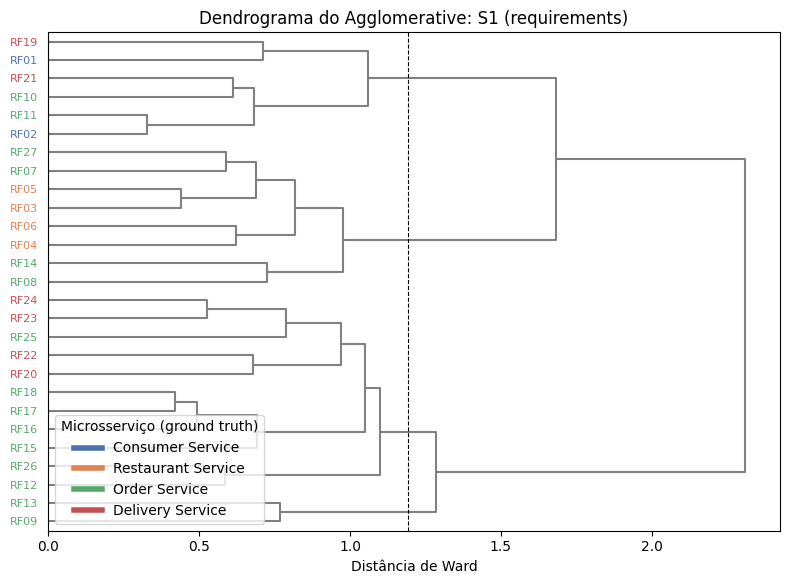

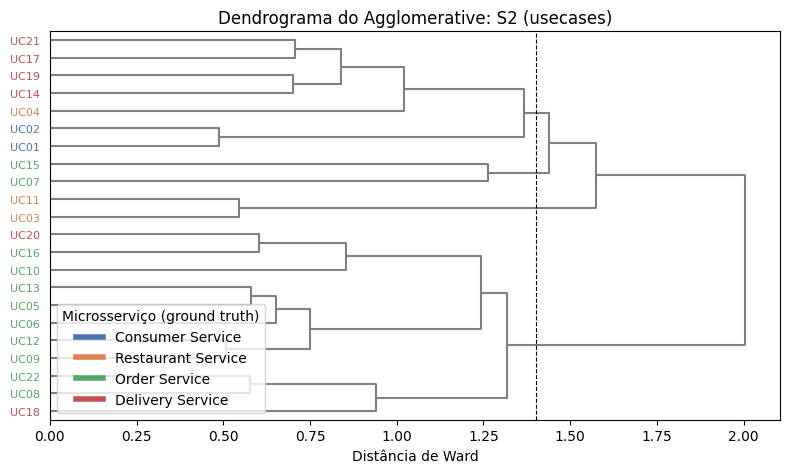

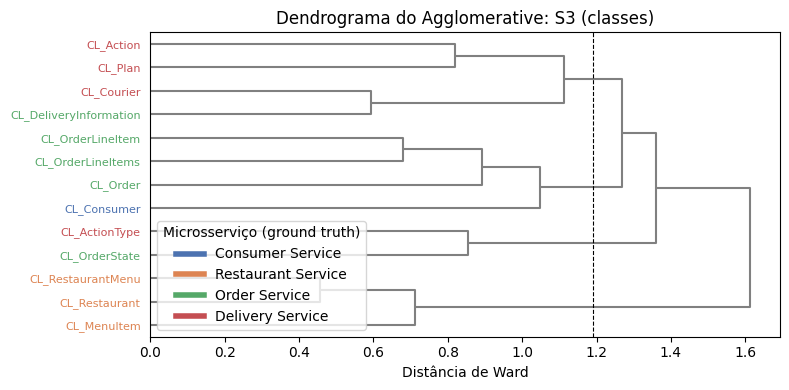

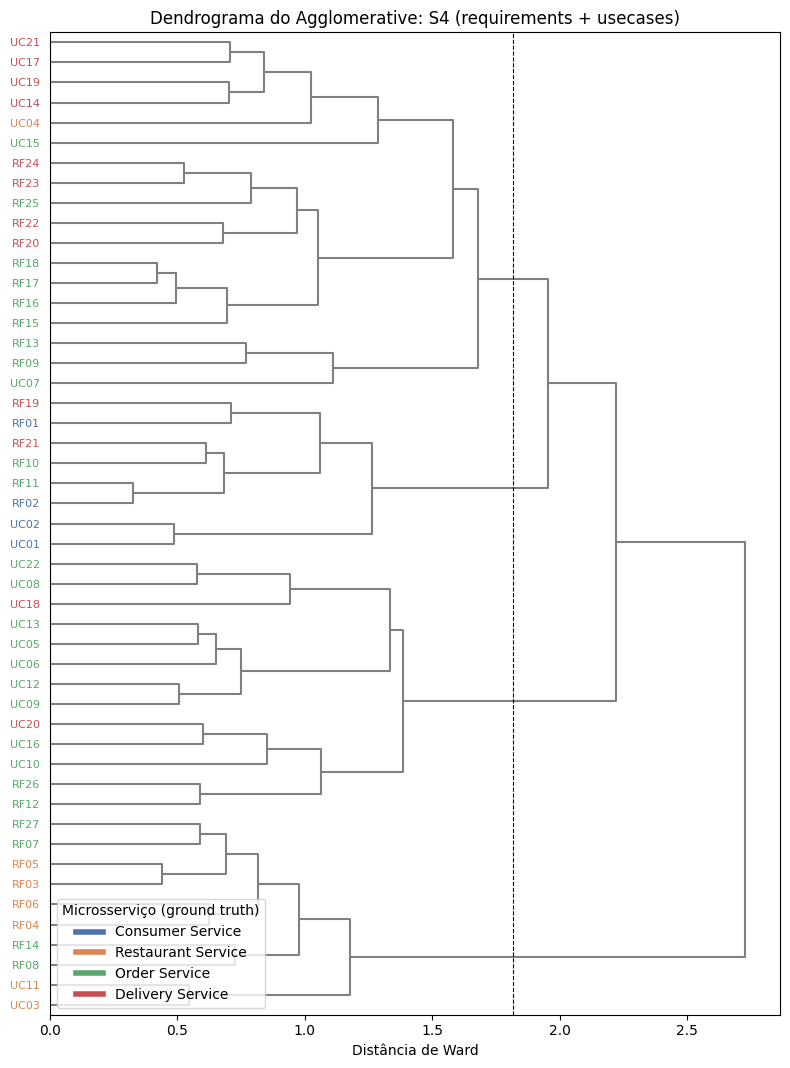

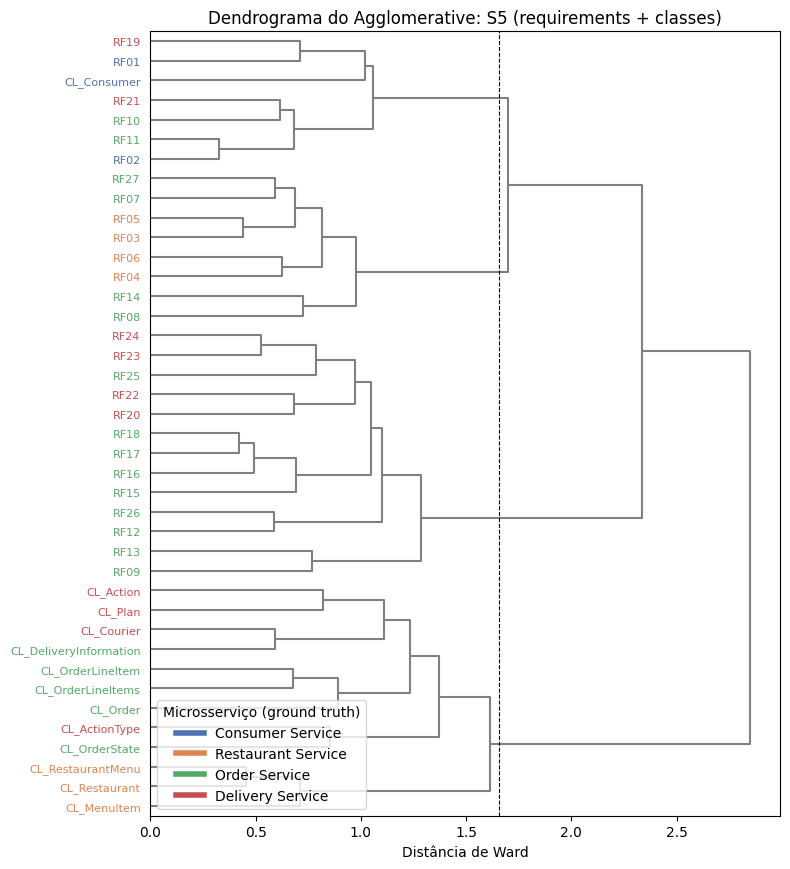

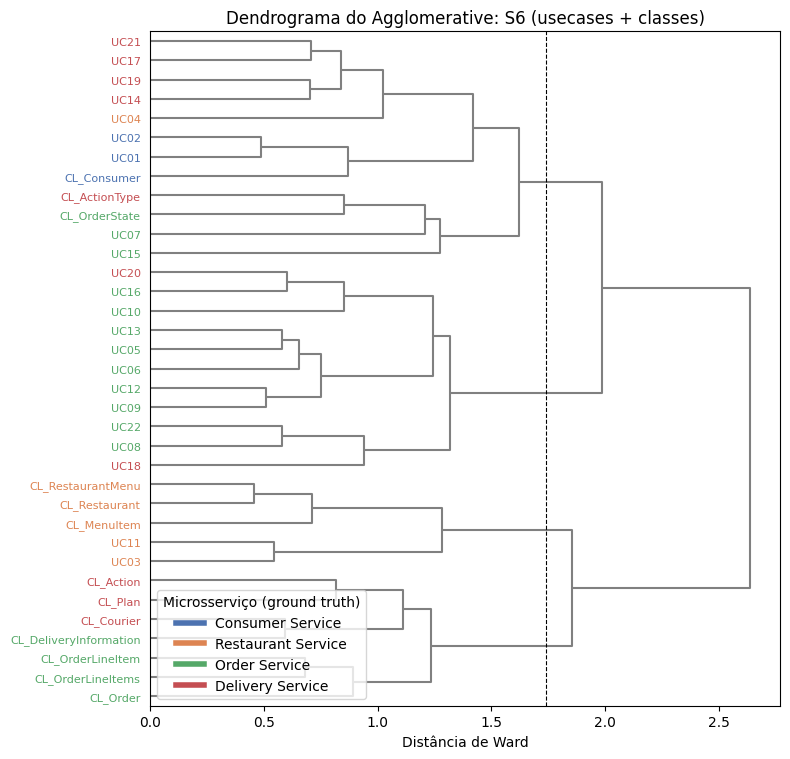

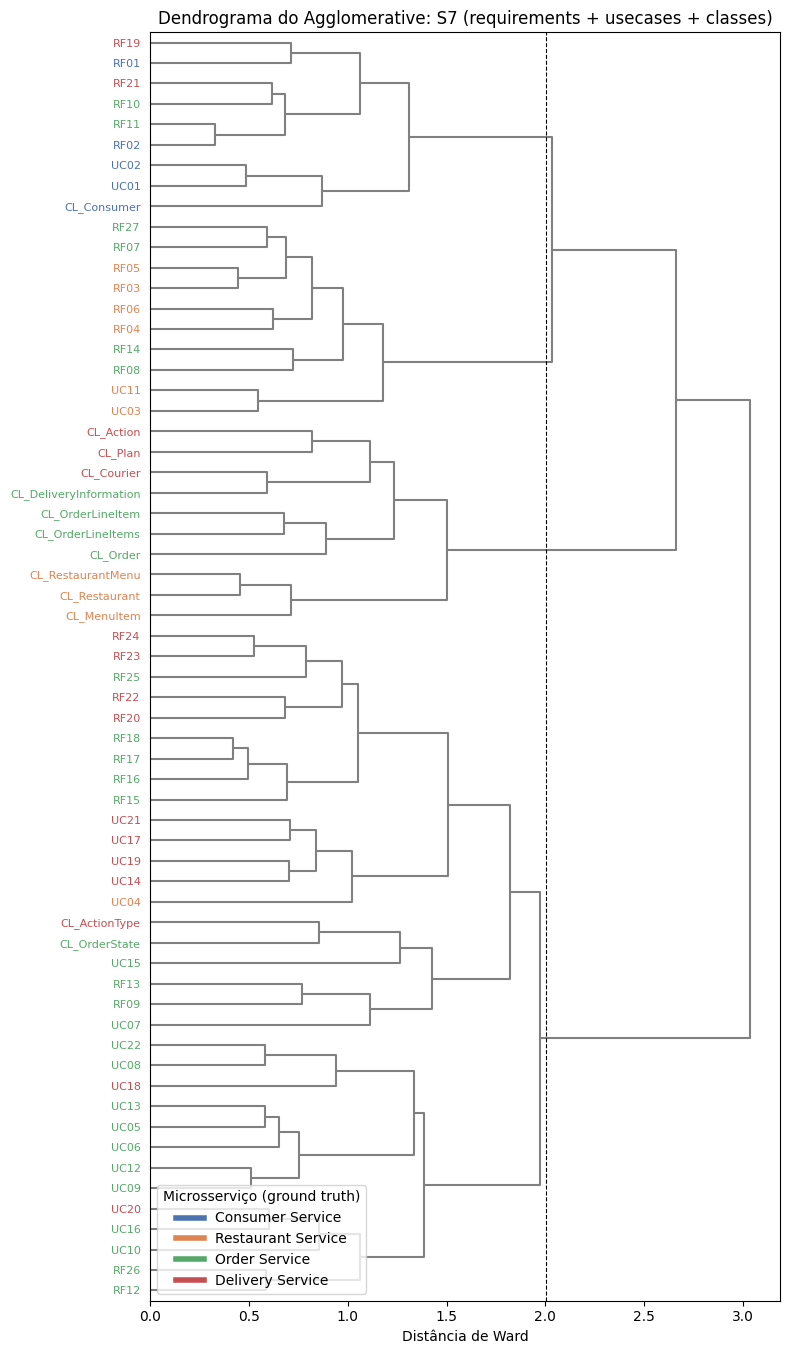

In [ ]:
def plot_dendrogram(sc_name):
    """Dendrograma (Ward) com folhas coloridas pelo microsserviço do ground truth e corte em k clusters."""
    sc = scenarios[sc_name]
    ids = sc["items"]["item_id"].tolist()
    services = dict(zip(ids, sc["y_true"]))
    Z = linkage(sc["X"], method=CONFIG["linkage"])

    fig, ax = plt.subplots(figsize=(8, max(4, 0.22 * len(ids))))
    dendrogram(Z, labels=ids, orientation="right", ax=ax, leaf_font_size=8,
               color_threshold=0, above_threshold_color="gray")
    for label in ax.get_ymajorticklabels():
        label.set_color(SERVICE_COLORS[services[label.get_text()]])

    k = CONFIG["n_clusters"]  # linha de corte que separa k clusters
    ax.axvline((Z[-(k - 1), 2] + Z[-k, 2]) / 2, color="black", linestyle="--", linewidth=0.8)

    handles = [plt.Line2D([0], [0], color=c, lw=4) for c in SERVICE_COLORS.values()]
    ax.legend(handles, SERVICE_COLORS.keys(), title="Microsserviço (ground truth)", loc="lower left")
    ax.set_title(f"Dendrograma do Agglomerative: {sc_name} ({' + '.join(CONFIG['scenarios'][sc_name])})")
    ax.set_xlabel("Distância de Ward")
    plt.tight_layout()
    plt.show()

for name in scenarios:
    plot_dendrogram(name)

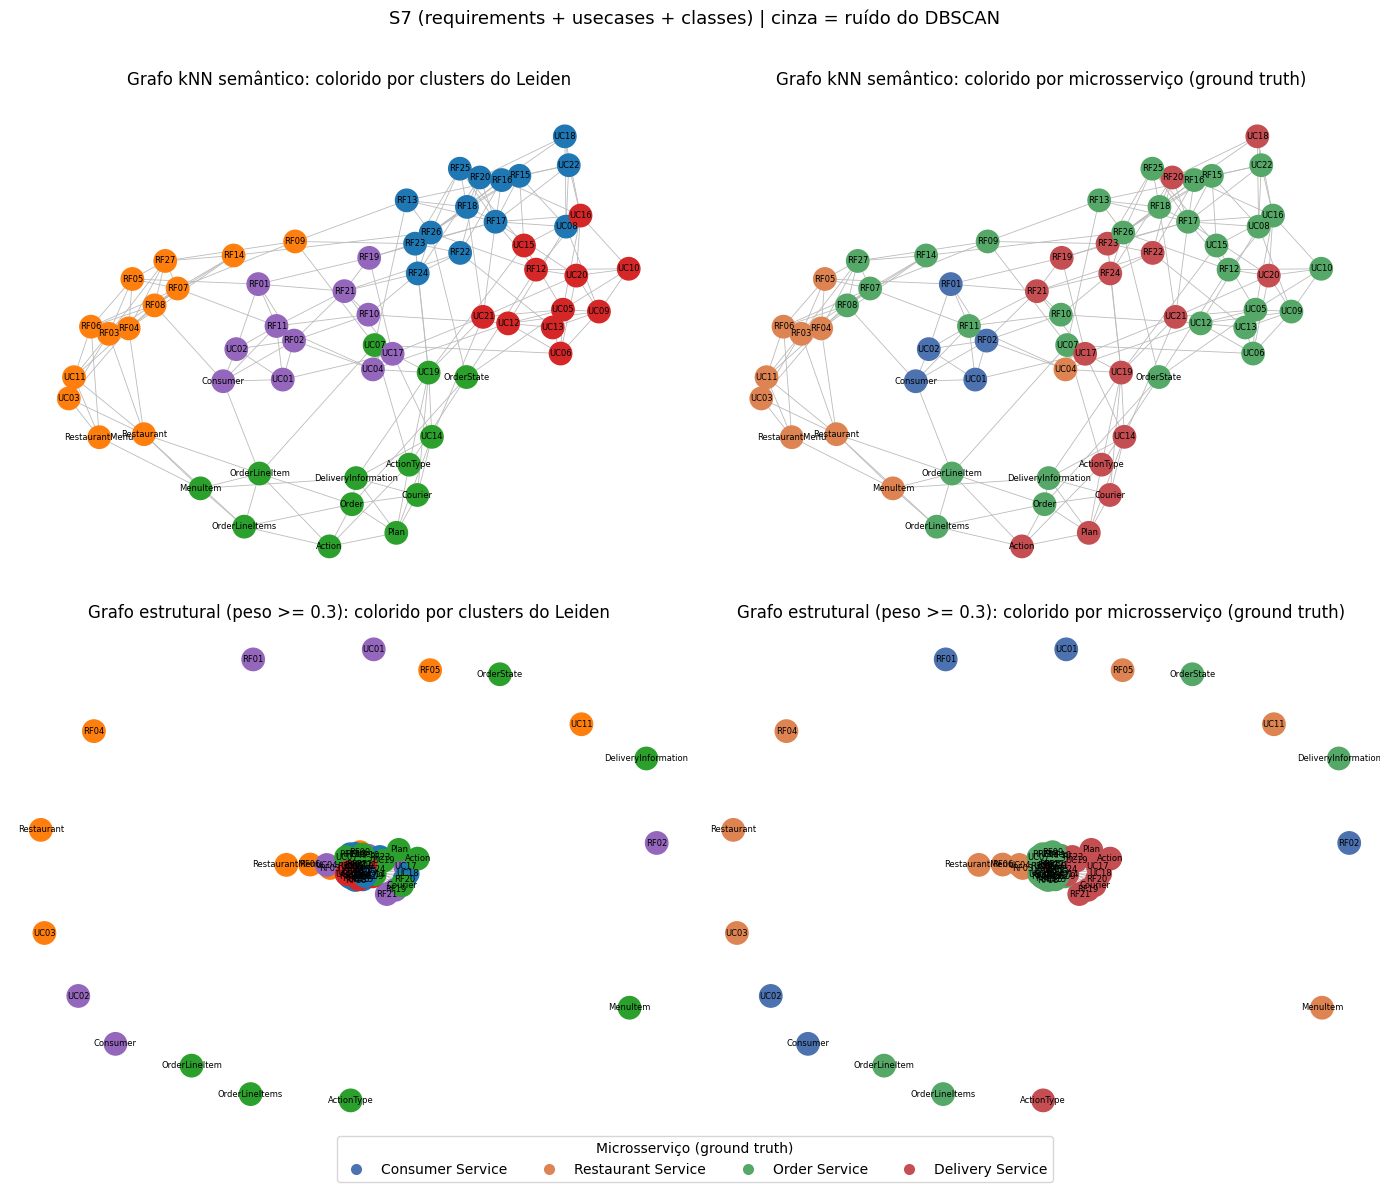

In [ ]:
CLUSTER_PALETTE = plt.cm.tab10.colors

def plot_graphs(sc_name, algo_name, min_weight=0.3):
    """Grafos kNN e estrutural, coloridos por cluster (ruído em cinza) e por serviço do ground truth."""
    sc = scenarios[sc_name]
    ids = sc["items"]["item_id"].tolist()
    labels = results[(sc_name, algo_name)]

    g = build_knn_graph(sc["X"], CONFIG["knn_k"])
    G_knn = nx.Graph()
    G_knn.add_nodes_from(range(len(ids)))
    G_knn.add_weighted_edges_from((a, b, w) for (a, b), w in zip(g.get_edgelist(), g.es["weight"]))

    W = structural_W[sc_name]
    G_str = nx.Graph()
    G_str.add_nodes_from(range(len(ids)))
    G_str.add_edges_from((i, j) for i in range(len(ids)) for j in range(i + 1, len(ids)) if W[i, j] >= min_weight)

    cluster_colors = ["lightgray" if c == -1 else CLUSTER_PALETTE[c % 10] for c in labels]
    service_colors = [SERVICE_COLORS[s] for s in sc["y_true"]]
    names = {i: item_id.replace("CL_", "") for i, item_id in enumerate(ids)}
    pos = {"knn": nx.spring_layout(G_knn, seed=CONFIG["seed"]), "str": nx.spring_layout(G_str, seed=CONFIG["seed"])}

    panels = [(G_knn, pos["knn"], "Grafo kNN semântico", cluster_colors, f"clusters do {algo_name}"),
              (G_knn, pos["knn"], "Grafo kNN semântico", service_colors, "microsserviço (ground truth)"),
              (G_str, pos["str"], f"Grafo estrutural (peso >= {min_weight})", cluster_colors, f"clusters do {algo_name}"),
              (G_str, pos["str"], f"Grafo estrutural (peso >= {min_weight})", service_colors, "microsserviço (ground truth)")]

    fig, axes = plt.subplots(2, 2, figsize=(14, 12))

    for ax, (G, layout, title, colors, subtitle) in zip(axes.ravel(), panels):
        nx.draw_networkx(G, layout, ax=ax, node_color=colors, labels=names,
                         font_size=6, node_size=260, edge_color="#bbbbbb", width=0.6)
        ax.set_title(f"{title}: colorido por {subtitle}")
        ax.axis("off")

    handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=9, label=s)
               for s, c in SERVICE_COLORS.items()]
    fig.legend(handles=handles, title="Microsserviço (ground truth)", loc="lower center", ncol=4)
    fig.suptitle(f"{sc_name} ({' + '.join(CONFIG['scenarios'][sc_name])}) | cinza = ruído do DBSCAN", fontsize=13)
    plt.tight_layout(rect=[0, 0.04, 1, 0.97])
    plt.show()

plot_graphs("S7", "Leiden")
# plot_graphs("S2", "K-Means"), plot_graphs("S4", "DBSCAN")  # outros exemplos

S2 | K-Means | ARI = 0.794



col_0,Consumer Service,Delivery Service,Order Service,Restaurant Service
row_0,,,,
0,0,1,8,0
1,0,4,0,0
2,0,0,0,2
3,2,0,0,0



Itens fora do serviço do seu cluster: ['UC20']
Itens removidos como ruído (cinza): ['UC04', 'UC07', 'UC10', 'UC15', 'UC18']
Cluster 0 (Order Service): ['UC05', 'UC06', 'UC08', 'UC09', 'UC12', 'UC13', 'UC16', 'UC20', 'UC22']
Cluster 1 (Delivery Service): ['UC14', 'UC17', 'UC19', 'UC21']
Cluster 2 (Restaurant Service): ['UC03', 'UC11']
Cluster 3 (Consumer Service): ['UC01', 'UC02']


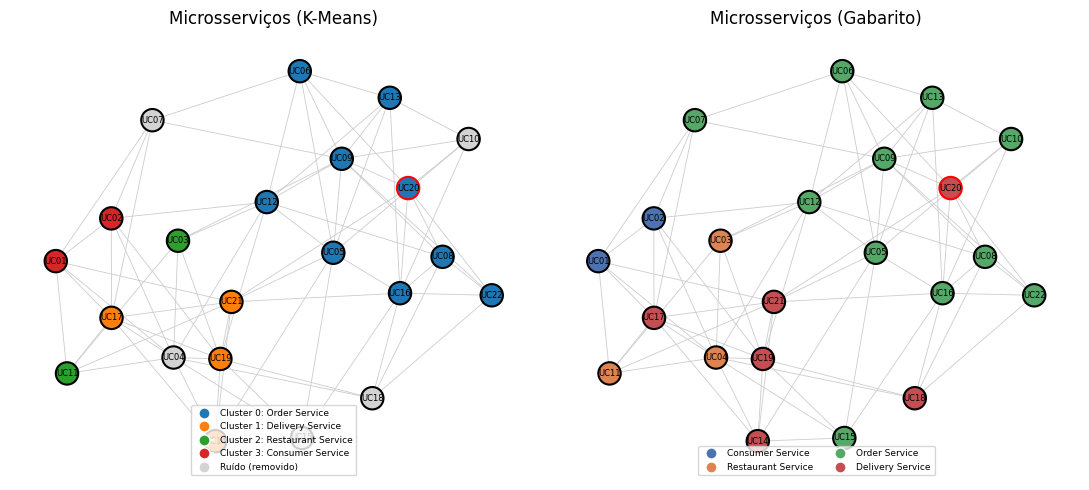

In [ ]:
def plot_best_result(sc_name="S2", algo="K-Means"):
    """Grafo kNN do melhor resultado: clusters nomeados pelo serviço majoritário x ground truth."""
    sc, run = scenarios[sc_name], common[(sc_name, algo)]
    ids = sc["items"]["item_id"].tolist()
    labels = np.where(run["mask"], results[(sc_name, algo)], -1)  # fora do subconjunto comum = -1

    # Cada cluster recebe o nome do serviço majoritário do ground truth
    ct = pd.crosstab(run["labels"], run["y_true"])
    cluster_name = ct.idxmax(axis=1).to_dict()
    print(f"{sc_name} | {algo} | ARI = {adjusted_rand_score(run['y_true'], run['labels']):.3f}\n")
    display(ct)

    # Itens cujo serviço difere do serviço majoritário do seu cluster
    wrong = {i for i, c, y in zip(ids, labels, sc["y_true"]) if c != -1 and cluster_name[c] != y}
    print("\nItens fora do serviço do seu cluster:", sorted(wrong) or "nenhum")
    print("Itens removidos como ruído (cinza):", [i for i, c in zip(ids, labels) if c == -1])
    for c in sorted(cluster_name):
        members = [i for i, l in zip(ids, labels) if l == c]
        print(f"Cluster {c} ({cluster_name[c]}): {members}")

    # Grafo kNN
    g = build_knn_graph(sc["X"], CONFIG["knn_k"])
    G = nx.Graph()
    G.add_nodes_from(range(len(ids)))
    G.add_edges_from(g.get_edgelist())
    pos = nx.spring_layout(G, seed=CONFIG["seed"])
    names = {i: item_id for i, item_id in enumerate(ids)}

    colors_cluster = ["lightgray" if c == -1 else plt.cm.tab10.colors[c % 10] for c in labels]
    colors_gt = [SERVICE_COLORS[s] for s in sc["y_true"]]
    edge_colors = ["red" if i in wrong else "black" for i in ids]

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, colors, title in zip(axes, [colors_cluster, colors_gt],
                                 [f"Microsserviços ({algo})", "Microsserviços (Gabarito)"]):
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#cccccc", width=0.6)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=260,
                               edgecolors=edge_colors, linewidths=1.5)
        nx.draw_networkx_labels(G, pos, labels=names, ax=ax, font_size=6)
        ax.set_title(title)
        ax.axis("off")

    h1 = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=plt.cm.tab10.colors[c % 10],
                     markersize=8, label=f"Cluster {c}: {cluster_name[c]}") for c in sorted(cluster_name)]
    h1.append(plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="lightgray", markersize=8, label="Ruído (removido)"))
    h2 = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=8, label=s)
          for s, c in SERVICE_COLORS.items()]
    axes[0].legend(handles=h1, loc="lower center", fontsize=6.5)
    axes[1].legend(handles=h2, loc="lower center", fontsize=6.5, ncol=2)
    plt.tight_layout()
    plt.savefig("figura1_melhor_resultado.png", dpi=300, bbox_inches="tight")
    plt.show()


plot_best_result("S2", "K-Means")

## 5.3 Síntese: contribuição das fontes e limitações

Medimos a contribuição de cada fonte, o ganho das combinações sobre a melhor fonte componente e se os clusters seguem o serviço ou a fonte do item. Todas as análises usam o **subconjunto comum**.

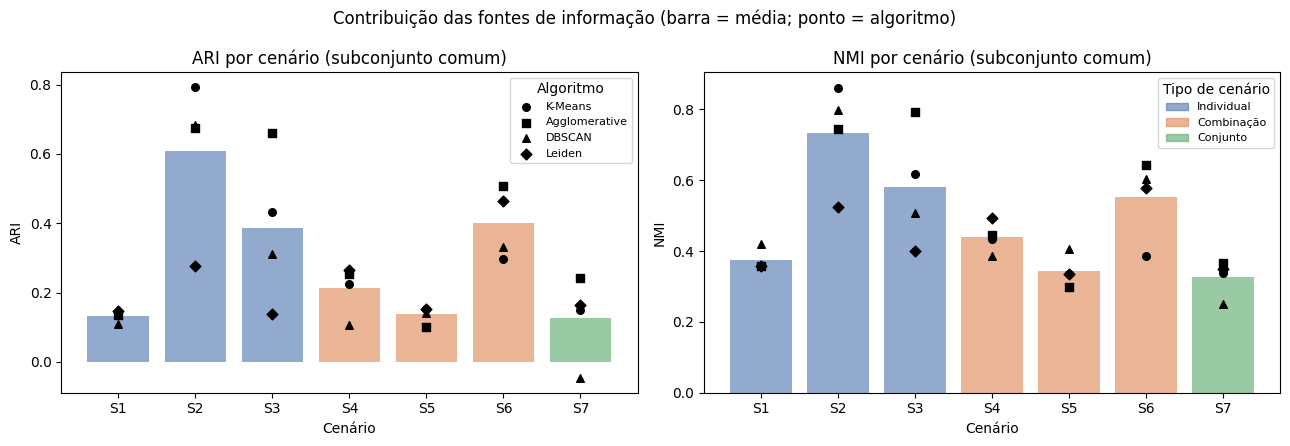

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, metric in zip(axes, ["ARI", "NMI"]):
    pv = df_metrics_common.pivot(index="cenário", columns="algoritmo", values=metric)
    ax.bar(pv.index, pv.mean(axis=1), color=[GROUP_COLORS[GROUPS[s]] for s in pv.index], alpha=0.6)

    for algo, marker in ALGO_MARKERS.items():
        ax.scatter(pv.index, pv[algo], marker=marker, color="black", s=30, label=algo)

    ax.set_title(f"{metric} por cenário (subconjunto comum)")
    ax.set_xlabel("Cenário")
    ax.set_ylabel(metric)

axes[0].legend(title="Algoritmo", fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.6) for c in GROUP_COLORS.values()]
axes[1].legend(handles, GROUP_COLORS.keys(), title="Tipo de cenário", fontsize=8)
fig.suptitle("Contribuição das fontes de informação (barra = média; ponto = algoritmo)")
plt.tight_layout()
plt.show()

In [ ]:
ari = df_metrics_common.pivot(index="cenário", columns="algoritmo", values="ARI")

rows = []

for sc, comps in COMPONENTS.items():
    best = ari.loc[comps].max()   # melhor fonte isolada, por algoritmo
    gain = ari.loc[sc] - best
    rows.append({"cenário": sc, "fontes": " + ".join(CONFIG["scenarios"][sc]),
                 "ARI médio": ari.loc[sc].mean(), "ARI médio do melhor componente": best.mean(),
                 "ganho médio": gain.mean(), "algoritmos com ganho (de 4)": int((gain > 0).sum())})

df_gain = pd.DataFrame(rows).round(3)
df_gain

,cenário,fontes,ARI médio,ARI médio do melhor componente,ganho médio,algoritmos com ganho (de 4)
0,S4,requirements + usecases,0.212,0.607,-0.395,0
1,S5,requirements + classes,0.137,0.387,-0.250,1
2,S6,usecases + classes,0.400,0.607,-0.207,1
3,S7,requirements + usecases + classes,0.127,0.607,-0.481,0


ARI vs serviço                        ARI vs fonte                 \
algoritmo  Agglomerative DBSCAN K-Means Leiden Agglomerative DBSCAN K-Means   
cenário                                                                       
S4                 0.253  0.108   0.224  0.264         0.147  0.290   0.194   
S5                 0.101  0.142   0.153  0.153         0.322  0.269   0.221   
S6                 0.507  0.332   0.298  0.464         0.343  0.522   0.528   
S7                 0.242 -0.047   0.149  0.163         0.196  0.549   0.370   

                  
algoritmo Leiden  
cenário           
S4         0.079  
S5         0.221  
S6         0.237  
S7         0.203

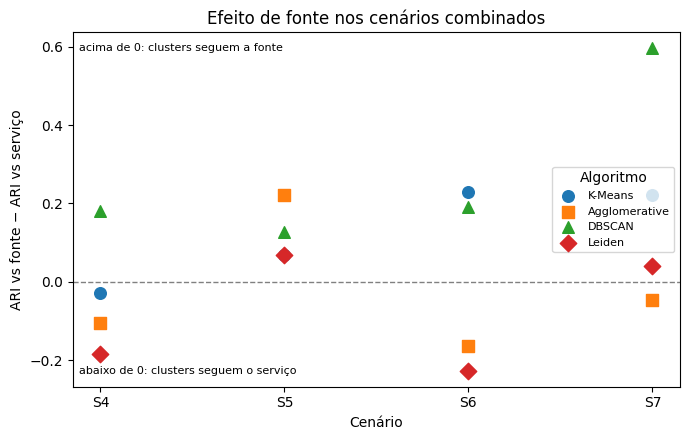

In [ ]:
rows = []

for (sc_name, algo), run in common.items():
    if len(CONFIG["scenarios"][sc_name]) < 2:
        continue

    rows.append({"cenário": sc_name, "algoritmo": algo,
                 "ARI vs serviço": adjusted_rand_score(run["y_true"], run["labels"]),
                 "ARI vs fonte": adjusted_rand_score(run["items"]["source"].values, run["labels"])})

df_source_effect = pd.DataFrame(rows)
display(df_source_effect.pivot(index="cenário", columns="algoritmo",
                               values=["ARI vs serviço", "ARI vs fonte"]).round(3))

# Figura: diferença de ARI (acima de 0 = clusters seguem a fonte)
se = df_source_effect.assign(diferença=df_source_effect["ARI vs fonte"] - df_source_effect["ARI vs serviço"])
fig, ax = plt.subplots(figsize=(7, 4.5))

for algo, marker in ALGO_MARKERS.items():
    d = se[se["algoritmo"] == algo]
    ax.scatter(d["cenário"], d["diferença"], marker=marker, s=70, label=algo)

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Efeito de fonte nos cenários combinados")
ax.set_xlabel("Cenário")
ax.set_ylabel("ARI vs fonte − ARI vs serviço")
ax.text(0.01, 0.97, "acima de 0: clusters seguem a fonte", transform=ax.transAxes, va="top", fontsize=8)
ax.text(0.01, 0.03, "abaixo de 0: clusters seguem o serviço", transform=ax.transAxes, va="bottom", fontsize=8)
ax.legend(title="Algoritmo", fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

In [ ]:
# Caso concreto: clusters x fonte e clusters x serviço (S7, Agglomerative)
run = common[("S7", "Agglomerative")]
print("S7 | Agglomerative: cluster x fonte")
display(pd.crosstab(run["labels"], run["items"]["source"]))
print("S7 | Agglomerative: cluster x serviço")
display(pd.crosstab(run["labels"], run["y_true"]))

# Itens de cada cluster do K-Means em S1 (para identificar o critério de agrupamento)
run = common[("S1", "K-Means")]

for c in sorted(set(run["labels"])):
    print(f"\nCluster {c}")

    for _, r in run["items"][run["labels"] == c].iterrows():
        print(f"  {r['item_id']} [{r['label']}] {r['text'][:90]}")

S7 | Agglomerative: cluster x fonte


source,classes,requirements,usecases
row_0,,,
0,0,11,11
1,0,6,2
2,7,0,0
3,0,7,2


S7 | Agglomerative: cluster x serviço


col_0,Consumer Service,Delivery Service,Order Service,Restaurant Service
row_0,,,,
0,0,7,15,0
1,4,2,2,0
2,0,1,3,3
3,0,0,3,6



Cluster 0
  RF02 [Consumer Service] O sistema deve permitir a consulta de consumidores cadastrados por meio de seu identificad
  RF10 [Order Service] O sistema deve permitir a consulta de um pedido específico por meio de seu identificador.
  RF11 [Order Service] O sistema deve permitir a consulta dos pedidos associados a um consumidor, utilizando seu 
  RF21 [Delivery Service] O sistema deve permitir a consulta das informações de um entregador cadastrado por meio de

Cluster 1
  RF12 [Order Service] O sistema deve permitir o cancelamento de pedidos que estejam no estado aprovado.
  RF15 [Order Service] O sistema deve permitir a atualização do estado de um pedido para indicar que seu preparo 
  RF16 [Order Service] O sistema deve permitir a atualização do estado de um pedido para indicar que ele está pro
  RF17 [Order Service] O sistema deve permitir o registro da retirada de um pedido pelo entregador, atualizando s
  RF18 [Order Service] O sistema deve permitir o registro da conclusão

## 5.4 Análise de sensibilidade

Repetimos o experimento variando **um fator por vez** a partir da configuração base: percentil do `eps` (60 e 90), `knn_k` (3 e 8), dez sementes (0 a 9, afetam K-Means e Leiden) e um segundo modelo de embeddings (`multilingual-e5-base`). Todos os resultados são reportados, sem escolher o melhor.

**Critérios de robustez (definidos antes de ver os dados):**

| Conclusão | Robusta se... |
|---|---|
| S2 é a melhor fonte isolada | S2 aparece primeiro na maioria das configurações |
| Combinar não supera a melhor fonte | os ganhos médios de S4 a S7 continuam negativos |
| Só o Leiden se beneficia de combinar | só o Leiden (ou nenhum) ganha |
| S7 fica no nível de S1 | S7 não fica claramente acima de S2 e S3 |

In [ ]:
SEEDS = list(range(10))
BASE = {"model": "mpnet", "eps_pct": CONFIG["dbscan_eps_percentile"], "knn_k": CONFIG["knn_k"], "seed": CONFIG["seed"]}

# O modelo E5 espera o prefixo "query: " em cada texto
EMB = {"mpnet": emb_by_id, "e5": embed_items("intfloat/multilingual-e5-base", prefix="query: ")}

def run_config(cfg):
    """Roda S1 a S7 numa configuração e avalia as 9 métricas no subconjunto comum."""
    rows = []

    for sc_name, sc in scenarios.items():
        X = scenario_matrix(sc["items"], EMB[cfg["model"]])
        by_algo = cluster_all(X, cfg["eps_pct"], cfg["knn_k"], cfg["seed"])

        if (by_algo["DBSCAN"] != -1).sum() < 4:  # subconjunto comum pequeno demais
            continue

        for algo, run in make_runs(sc, X, by_algo, "common").items():
            rows.append({"config": cfg["name"], "cenário": sc_name, "algoritmo": algo,
                         "itens": int(run["mask"].sum()), **evaluate(run, structural_W[sc_name])})

    return pd.DataFrame(rows)

configs = [dict(BASE, name="base")]
configs += [dict(BASE, name=f"eps_p{p}", eps_pct=p) for p in (60, 90)]
configs += [dict(BASE, name=f"knn_k{k}", knn_k=k) for k in (3, 8)]
configs += [dict(BASE, name=f"seed{s}", seed=s) for s in SEEDS]
configs += [dict(BASE, name="modelo_e5", model="e5")]

df_sens = pd.concat([run_config(c) for c in configs], ignore_index=True)

# Conferência: a base deve reproduzir o resultado do subconjunto comum
b = df_sens[df_sens["config"] == "base"].set_index(["cenário", "algoritmo"])["ARI"]
o = df_metrics_common.set_index(["cenário", "algoritmo"])["ARI"].reindex(b.index)
print("Base reproduz o resultado anterior:", np.allclose(b, o, atol=1e-6))
print(f"{len(configs)} configurações, {len(df_sens)} linhas")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Base reproduz o resultado anterior: True
16 configurações, 448 linhas


In [ ]:
fixed = df_sens[~df_sens["config"].str.startswith("seed")]

print("ARI médio entre algoritmos (subconjunto comum de cada configuração)")
display(fixed.groupby(["config", "cenário"])["ARI"].mean().unstack().round(3))

print("Itens retidos pelo DBSCAN (tamanho do subconjunto comum)")
display(fixed.groupby(["config", "cenário"])["itens"].first().unstack())

print("Nº de clusters do DBSCAN (1 = colapso)")
display(fixed[fixed["algoritmo"] == "DBSCAN"].groupby(["config", "cenário"])["clusters"].first().unstack())

seeds_df = df_sens[df_sens["config"].str.startswith("seed")]
print("ARI por semente: média e desvio-padrão (só K-Means e Leiden variam)")
display(seeds_df.groupby(["cenário", "algoritmo"])["ARI"].agg(["mean", "std"]).round(3).unstack("algoritmo"))

ARI médio entre algoritmos (subconjunto comum de cada configuração)


cenário,S1,S2,S3,S4,S5,S6,S7
config,,,,,,,
base,0.131,0.607,0.385,0.212,0.137,0.400,0.127
eps_p60,0.121,0.684,0.514,0.191,0.146,0.438,0.195
eps_p90,0.133,0.432,0.256,0.168,0.123,0.269,0.142
knn_k3,0.127,0.662,0.421,0.195,0.128,0.437,0.120
knn_k8,0.128,0.647,0.429,0.194,0.137,0.347,0.127
modelo_e5,0.063,0.359,0.290,-0.073,0.159,0.194,0.080


Itens retidos pelo DBSCAN (tamanho do subconjunto comum)


cenário,S1,S2,S3,S4,S5,S6,S7
config,,,,,,,
base,20,17,10,37,30,26,46
eps_p60,16,13,8,29,24,22,37
eps_p90,24,19,12,44,36,31,55
knn_k3,20,17,10,37,30,26,46
knn_k8,20,17,10,37,30,26,46
modelo_e5,20,16,10,38,30,26,46


Nº de clusters do DBSCAN (1 = colapso)


cenário,S1,S2,S3,S4,S5,S6,S7
config,,,,,,,
base,5,6,2,4,6,6,6
eps_p60,5,4,3,9,7,8,11
eps_p90,1,2,3,1,4,2,3
knn_k3,5,6,2,4,6,6,6
knn_k8,5,6,2,4,6,6,6
modelo_e5,3,3,2,5,2,6,7


ARI por semente: média e desvio-padrão (só K-Means e Leiden variam)


mean                                 std                 \
algoritmo Agglomerative DBSCAN K-Means Leiden Agglomerative DBSCAN K-Means   
cenário                                                                      
S1                0.135  0.108   0.140  0.147           0.0    0.0   0.049   
S2                0.674  0.684   0.642  0.277           0.0    0.0   0.089   
S3                0.659  0.312   0.445  0.148           0.0    0.0   0.043   
S4                0.253  0.108   0.215  0.219           0.0    0.0   0.012   
S5                0.101  0.142   0.146  0.151           0.0    0.0   0.036   
S6                0.507  0.332   0.442  0.454           0.0    0.0   0.055   
S7                0.242 -0.047   0.179  0.173           0.0    0.0   0.101   

                  
algoritmo Leiden  
cenário           
S1         0.000  
S2         0.000  
S3         0.010  
S4         0.043  
S5         0.015  
S6         0.032  
S7         0.016

In [ ]:
def check_claims(df):
    """Resume as conclusões principais de uma configuração (ARI no subconjunto comum)."""
    ari = df.pivot_table(index="cenário", columns="algoritmo", values="ARI")

    if not set(scenarios) <= set(ari.index):
        return None

    mean = ari.mean(axis=1)
    gains = {sc: ari.loc[sc] - ari.loc[comps].max() for sc, comps in COMPONENTS.items()}
    winners = sorted({a for g in gains.values() for a in g.index[g > 0]})

    return {
        "ordem das fontes isoladas": " > ".join(mean[["S1", "S2", "S3"]].sort_values(ascending=False).index),
        "melhor cenário": mean.idxmax(),
        **{f"ganho médio {sc}": gains[sc].mean() for sc in COMPONENTS},
        "algoritmos que ganham ao combinar": ", ".join(winners) if winners else "nenhum",
    }

rows = {name: check_claims(g) for name, g in df_sens.groupby("config")}
df_claims = pd.DataFrame({k: v for k, v in rows.items() if v is not None}).T
display(df_claims)

skipped = [k for k, v in rows.items() if v is None]

if skipped:
    print("Configurações sem subconjunto comum suficiente em algum cenário:", skipped)

,ordem das fontes isoladas,melhor cenário,ganho médio S4,ganho médio S5,ganho médio S6,ganho médio S7,algoritmos que ganham ao combinar
base,S2 > S3 > S1,S2,-0.395274,-0.250431,-0.20742,-0.480891,Leiden
eps_p60,S2 > S3 > S1,S2,-0.492643,-0.367985,-0.24565,-0.489094,Leiden
eps_p90,S2 > S3 > S1,S2,-0.263575,-0.147736,-0.162518,-0.290151,Leiden
knn_k3,S2 > S3 > S1,S2,-0.467338,-0.292641,-0.224825,-0.54203,Leiden
knn_k8,S2 > S3 > S1,S2,-0.45226,-0.29171,-0.299293,-0.52014,nenhum
modelo_e5,S2 > S3 > S1,S2,-0.431729,-0.130292,-0.172336,-0.286958,nenhum
seed0,S2 > S3 > S1,S2,-0.346245,-0.250431,-0.128372,-0.423414,Leiden
seed1,S2 > S3 > S1,S2,-0.36121,-0.252791,-0.142018,-0.412459,Leiden
seed2,S2 > S3 > S1,S2,-0.395274,-0.252791,-0.18571,-0.442257,Leiden
seed3,S2 > S3 > S1,S2,-0.399687,-0.251846,-0.153381,-0.480774,Leiden


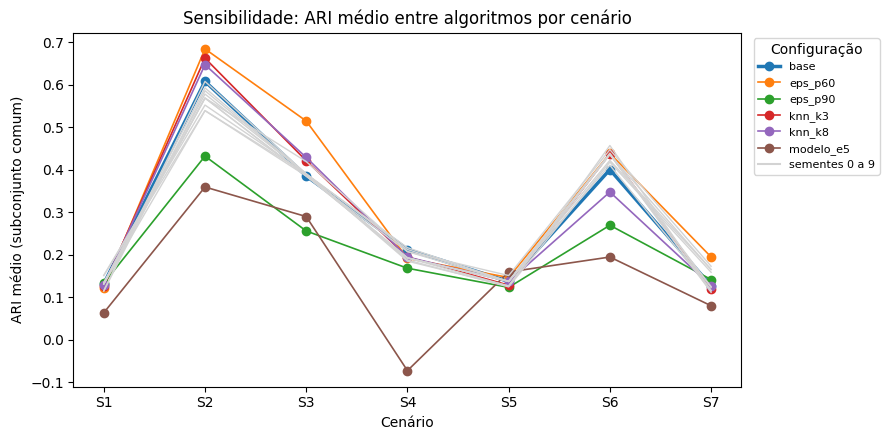

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))

for name, g in df_sens.groupby("config"):
    mean = g.groupby("cenário")["ARI"].mean()
    if name.startswith("seed"):
        ax.plot(mean.index, mean.values, color="lightgray", linewidth=1)
    else:
        ax.plot(mean.index, mean.values, marker="o", linewidth=2.5 if name == "base" else 1.2, label=name)

ax.plot([], [], color="lightgray", label="sementes 0 a 9")
ax.set_title("Sensibilidade: ARI médio entre algoritmos por cenário")
ax.set_xlabel("Cenário")
ax.set_ylabel("ARI médio (subconjunto comum)")
ax.legend(title="Configuração", fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()